# Merge IRGA72 Level-1 fluxes (2016-2026.09)

**notebook version**: `2` (25 Oct 2026)

## ℹ️ About this notebook

Merges the EddyPro *FLUXNET* output files of the **Level-1** (final) flux calculations for the
**IRGA72** gas analyser into one continuous 30MIN dataframe and stores it in the external data
folder as parquet. The flux processing chain joins it with the meteo data in its input notebook
(`30_FLUX_PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09`), and `80_FINALIZE` takes it
into the collection of all data.

No value is computed or corrected here. Three things change in the incoming data:

- Where two consecutive runs overlap, each record is taken whole from one of them, split at
  midnight (see the timestamp section below).
- The six biomet columns that every run exported are dropped.
- Columns that hold no value anywhere in the merged record are dropped.

The record is cut at `PERIOD_END`, the half-hour ending at midnight on 30 September 2026.

***

## 📇 Data sources

EddyPro *FLUXNET* output files (`*_adv.csv`), one per processing run, in the external data folder
under `0_data/IRGA72-Level-1_fluxnet_2016-2026.09/`. The whole `IRGA72` record was re-run in
September and October 2026, one run per setup period.

A run covers one or more **setup periods**, not a calendar year: `2017_1+2` is a single run over
setup periods 1 and 2 of 2017, and a run boundary marks a hardware or configuration change. The
merge therefore works on the timestamps inside the files, not on the file names. The setup periods,
and the numbered notes that go with them, are documented in `docs/Yearly_Notes.md` and on the
SwissFluxNet page it links to.

Four setup periods have no file in this folder:

- **`2019_2`** (11 - 17 Jan 2019): the LI-7200 was replaced on 11 January 2019 and both units were
  defective, so the period has no usable gas fluxes. No sonic-only run for `H` has been made for it.
- **`2019_3`** (17 Jan - 20 Mar 2019) was measured with the LI-7500 (`IRGA75`), which stood in for
  the defective LI-7200. It is processed with the other `IRGA75` runs.
- **`2021_2` and `2022_1`** (13 Dec 2021 - 7 Feb 2022) have no output at all: the raw data was
  logged in an unknown format and the conversion fails on an unrecognised record length.

These are the two long gaps of the merged record, 69 and 56 days, and the checks below assert that
there are no others.

**`2018_3`** (19 May - 7 Jun 2018) is a **sonic-only** run. The LI-7200 flow module had failed, so
the run contributes `H` and no `FC` or `LE`.

**The wrong calibration gas.** All `IRGA72` CO2 concentrations between 14 December 2017 and
15 March 2019 were measured against a wrong calibration gas, and the correction is a factor 0.974
on the CO2 concentration before the fluxes are calculated. It was applied during the conversion
of the raw data to ASCII with bico, so these runs read corrected concentrations.

**The biomet columns.** Every run exported its six biomet inputs (`TA_1_1_1`, `RH_1_1_1`,
`PA_1_1_1`, `SW_IN_1_1_1`, `LW_IN_1_1_1`, `PPFD_IN_1_1_1`) into the FLUXNET file. They are dropped:
the meteo variables come from the `10_METEO` products, not from the EddyPro output.

## 🕐 Timestamp convention and run overlaps

The EddyPro output carries `TIMESTAMP_START` and `TIMESTAMP_END`. Each file is read with
`output_middle_timestamp=True`, so the merged record is indexed on `TIMESTAMP_MIDDLE`, the same
convention as the Level-0 merge and the meteo products. Timestamps are used as written by EddyPro;
nothing is shifted here.

**Runs that meet at a year boundary overlap by six hours.** Both include the raw file that starts
at 19:00 on 31 December, so both write the 12 half-hours from 31 December 19:15 to 1 January 00:45.
They are separate runs and their values there differ. `MultiDataFileReader` merges several files
with `combine_first`, cell by cell, which keeps the earlier run's value and fills only its gaps from
the later run, so a single record could combine `FC` from one run with `LE` from the other. Each
run is therefore read on its own, and each record is taken whole from one run: records before
midnight from the earlier run, records from midnight on from the later one. Each calendar year then
comes from the run made for it.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
# The Level-1 EddyPro FLUXNET output files. They live in the external (untracked) data folder and
# are addressed by absolute path, so the notebook does not depend on the working directory.
SOURCEDIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\workflow\0_data\IRGA72-Level-1_fluxnet_2016-2026.09")
SOURCEPATTERN = "*_adv.csv"  # the FLUXNET output files; anything else in that folder is ignored
FILETYPE = 'EDDYPRO-FLUXNET-CSV-30MIN'

# The runs expected in SOURCEDIR, named by the part of the file name before '_eddypro', in time
# order. 2019_2, 2019_3, 2021_2 and 2022_1 have no file on purpose (see the data sources above).
EXPECTED_RUNS = [
    '2016_2_IRGA72', '2016_3_IRGA72', '2017_1+2_IRGA72', '2018_1_IRGA72', '2018_2_IRGA72',
    '2018_3_SONIC', '2018_4+2019_1_IRGA72', '2019_4_IRGA72', '2020_IRGA72', '2021_1_IRGA72',
    '2022_2_IRGA72', '2022_3_IRGA72', '2022_4_IRGA72', '2023_1_IRGA72', '2023_2_IRGA72',
    '2024_IRGA72', '2025_IRGA72', '2026_IRGA72',
]
SONIC_ONLY_RUNS = ['2018_3_SONIC']  # runs without gas analyser data: H, no FC and no LE

# --- Period ------------------------------------------------------------------------------------
# TIMESTAMP_MIDDLE of the last record kept. The 2026_1 run ends at the end of its last raw file,
# 1 October 2026 00:45, past the end of the period the file name claims.
PERIOD_END = '2026-09-30 23:45:00'

# --- Output ------------------------------------------------------------------------------------
# Data files carry the same numeric prefix and the same relative path as the notebook producing
# them, in the external data folder.
OUTNAME = "99_IRGA72_L1_MERGED_2016-2026.09"
OUTPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\20_L1_FLUXES\IRGA72")

# --- Biomet columns ----------------------------------------------------------------------------
# Every Level-1 run wrote its biomet inputs into the EC output. They belong to the meteo products
# in 10_METEO. The drop is guarded below by a scan of the source file headers.
DROPCOLS = ['TA_1_1_1', 'RH_1_1_1', 'PA_1_1_1', 'SW_IN_1_1_1', 'LW_IN_1_1_1', 'PPFD_IN_1_1_1']

# --- Checks ------------------------------------------------------------------------------------
REQUIRED_TIME_RESOLUTION = '30min'
# The longest overlap two runs may have: one six-hour raw file. A longer one means a duplicated or
# misnamed run rather than a shared boundary file.
MAX_OVERLAP_RECORDS = 12
# Stretches longer than one day that no run covers, as (first, last) missing TIMESTAMP_MIDDLE. Both
# are explained in the data sources; any other long gap raises.
EXPECTED_LONG_GAPS = [('2019-01-10 15:15', '2019-03-20 18:45'),
                      ('2021-12-13 19:15', '2022-02-07 10:45')]
EXPECTED_YEARS = list(range(2016, 2027))  # every year the merged record must carry FC for
FLUXCOLS = ['FC', 'LE', 'H']

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import textwrap
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from diive.core.io.filereader import search_files, MultiDataFileReader
from diive.core.io.files import save_parquet, load_parquet

pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
# The reader builds its frames column by column and warns about fragmentation on every file.
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)


def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-25 02:03:34
diive version: v0.93.0


## 📂 Source files

In [3]:
sourcefiles = search_files(searchdirs=SOURCEDIR, pattern=SOURCEPATTERN)

# An empty result reads exactly like a folder that has not been updated yet, so it raises instead
# of merging nothing and writing an empty product.
assert len(sourcefiles) > 0, f"no files matching {SOURCEPATTERN} found in {SOURCEDIR}"

RUNS = {_f.name.split('_eddypro')[0]: _f for _f in sorted(sourcefiles)}
assert len(RUNS) == len(sourcefiles), "two source files share a run label"
assert list(RUNS) == EXPECTED_RUNS, (
    f"the runs found are not EXPECTED_RUNS in that order. "
    f"Missing: {sorted(set(EXPECTED_RUNS) - set(RUNS))}; "
    f"not expected: {sorted(set(RUNS) - set(EXPECTED_RUNS))}")

print(f"Found {len(RUNS)} runs in {SOURCEDIR}:")
for _run, _f in RUNS.items():
    print(f"  {_run:<22} {_f.name}")

Found 18 runs in F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\0_data\IRGA72-Level-1_fluxnet_2016-2026.09:
  2016_2_IRGA72          2016_2_IRGA72_eddypro_CH-LAE_2016_2_FR-20261021-175449_fluxnet_2026-10-22T030718_adv.csv
  2016_3_IRGA72          2016_3_IRGA72_eddypro_CH-LAE_2016_3_FR-20261019-195550_fluxnet_2026-10-20T141258_adv.csv
  2017_1+2_IRGA72        2017_1+2_IRGA72_eddypro_CH-LAE_2017_1+2_FR-20261019-195156_fluxnet_2026-10-20T234243_adv.csv
  2018_1_IRGA72          2018_1_IRGA72_eddypro_CH-LAE_2018_1_FR-20261021-175903_fluxnet_2026-10-21T200318_adv.csv
  2018_2_IRGA72          2018_2_IRGA72_eddypro_CH-LAE_2018_2_FR-20261019-194911_fluxnet_2026-10-20T040040_adv.csv
  2018_3_SONIC           2018_3_SONIC_eddypro_CH-LAE_2018_3_FR-20261021-180146_fluxnet_2026-10-21T191544_adv.csv
  2018_4+2019_1_IRGA72   2018_4+2019_1_IRGA72_eddypro_CH-LAE_2018_4+2019_1_FR-20261019-193809_fluxnet_2026-10-20T103328_adv.csv
  2019_4_IRGA72          2019_4_IRGA72_ed

## 🧹 The biomet columns

The guard reads the header of every source file. All runs must carry the six biomet columns, and no
run may carry another column of the same `_1_1_1` form, which would be a biomet input this list
does not know about.

In [4]:
for _run, _f in RUNS.items():
    with open(_f, encoding='utf-8') as _fh:
        _header = _fh.readline().strip().split(',')
    _biomet = [_c for _c in _header if _c.endswith('_1_1_1')]
    assert sorted(_biomet) == sorted(DROPCOLS), (
        f"{_run} carries the biomet columns {sorted(_biomet)}, expected exactly {sorted(DROPCOLS)}")
print(f"All {len(RUNS)} runs carry exactly the {len(DROPCOLS)} biomet columns: {', '.join(DROPCOLS)}")

All 18 runs carry exactly the 6 biomet columns: TA_1_1_1, RH_1_1_1, PA_1_1_1, SW_IN_1_1_1, LW_IN_1_1_1, PPFD_IN_1_1_1


## 🔗 Read the runs

In [5]:
%%time
# One reader per run, so that no two runs are merged cell by cell (see the timestamp section).
runs = {}
for _run, _f in RUNS.items():
    runs[_run] = MultiDataFileReader(filepaths=[_f], filetype=FILETYPE,
                                     output_middle_timestamp=True).data_df

> Reading file 
2016_2_IRGA72_eddypro_CH-LAE_2016_2_FR-20261021-175449_fluxnet_2026-10-22T030718_adv.csv ...

> Reading file 
2016_3_IRGA72_eddypro_CH-LAE_2016_3_FR-20261019-195550_fluxnet_2026-10-20T141258_adv.csv ...

> Reading file 
2017_1+2_IRGA72_eddypro_CH-LAE_2017_1+2_FR-20261019-195156_fluxnet_2026-10-20T234243_adv.csv ...

> Reading file 
2018_1_IRGA72_eddypro_CH-LAE_2018_1_FR-20261021-175903_fluxnet_2026-10-21T200318_adv.csv ...

> Reading file 
2018_2_IRGA72_eddypro_CH-LAE_2018_2_FR-20261019-194911_fluxnet_2026-10-20T040040_adv.csv ...

...

> Reading file 
2023_2_IRGA72_eddypro_CH-LAE_2023_2_FR-20260902-173626_fluxnet_2026-09-03T131942_adv.csv ...

> Reading file 
2024_IRGA72_eddypro_CH-LAE_2024_FR-20260902-173438_fluxnet_2026-09-03T173959_adv.csv ...

> Reading file 
2025_IRGA72_eddypro_CH-LAE_2025_FR-20260902-173353_fluxnet_2026-09-03T184152_adv.csv ...

> Reading file 
2026_IRGA72_eddypro_CH-LAE_2026_1_FR-20261023-141128_fluxnet_2026-10-24T114032_adv.csv ...

CPU times: total: 48.1 s
Wall time: 50.4 s


### 📋 Table: the runs as read

In [6]:
_rows = []
for _run, _df in runs.items():
    _rows.append({'run': _run, 'first': _df.index[0], 'last': _df.index[-1], 'records': len(_df),
                  **{_c: int(_df[_c].notna().sum()) if _c in _df else 0 for _c in FLUXCOLS},
                  'columns': _df.shape[1]})
RUNTABLE = pd.DataFrame(_rows).set_index('run')
tabcap("every run as read from its file: its first and last TIMESTAMP_MIDDLE, its records, the "
       "records holding FC, LE and H, and its number of columns")
display(RUNTABLE)

_starts = RUNTABLE['first']
assert _starts.is_monotonic_increasing and _starts.is_unique, "the runs are not in time order"
for _run, _df in runs.items():
    assert not _df.index.duplicated().any(), f"{_run} has duplicate timestamps"
    _steps = _df.index.to_series().diff().dropna().unique()
    assert len(_steps) == 1 and _steps[0] == pd.Timedelta(REQUIRED_TIME_RESOLUTION), (
        f"{_run} is not on a continuous {REQUIRED_TIME_RESOLUTION} index")
    if _run in SONIC_ONLY_RUNS:
        assert RUNTABLE.loc[_run, 'FC'] == 0 and RUNTABLE.loc[_run, 'LE'] == 0, (
            f"{_run} is declared sonic-only but carries gas fluxes")
        assert RUNTABLE.loc[_run, 'H'] > 0, f"{_run} is declared sonic-only but carries no H"
    else:
        assert RUNTABLE.loc[_run, 'FC'] > 0, f"{_run} carries no FC"

Table - every run as read from its file: its first and last TIMESTAMP_MIDDLE, its records, the
records holding FC, LE and H, and its number of columns



,first,last,records,FC,LE,H,columns
run,,,,,,,
2016_2_IRGA72,2016-01-11 15:45:00,2016-05-26 06:45:00,6511,5936,6116,6378,496
2016_3_IRGA72,2016-05-26 07:15:00,2017-01-01 00:45:00,10548,10444,10444,10500,496
2017_1+2_IRGA72,2016-12-31 19:15:00,2018-01-01 00:45:00,17532,17078,16748,17297,496
2018_1_IRGA72,2017-12-31 19:15:00,2018-01-31 10:45:00,1472,1209,1146,1337,496
2018_2_IRGA72,2018-01-31 11:45:00,2018-05-19 00:45:00,5163,5119,5129,5130,488
2018_3_SONIC,2018-05-19 01:15:00,2018-06-07 12:45:00,936,0,0,934,490
2018_4+2019_1_IRGA72,2018-06-07 13:15:00,2019-01-10 14:45:00,10420,9820,9978,10257,488
2019_4_IRGA72,2019-03-20 19:15:00,2020-01-01 00:45:00,13740,13365,13427,13526,488
2020_IRGA72,2019-12-31 19:15:00,2021-01-01 00:45:00,17580,16135,16241,17445,488


## ✂️ Run overlaps

Every pair of consecutive runs whose periods overlap is split at the one midnight inside the
overlap. The table reports what the choice decides: the largest difference between the two runs
over the records where both hold a value.

In [7]:
# KEEP[run] = (first, last) TIMESTAMP_MIDDLE taken from that run; None means the run's own end.
KEEP = {_run: [None, None] for _run in runs}
_rows = []
_names = list(runs)
for _a, _b in zip(_names, _names[1:]):
    _ov = runs[_a].index.intersection(runs[_b].index)
    if len(_ov) == 0:
        continue
    assert len(_ov) <= MAX_OVERLAP_RECORDS, f"{_a} and {_b} overlap by {len(_ov)} records"
    # The overlap must be one stretch at the end of the earlier run and the start of the later.
    assert _ov[0] == runs[_b].index[0] and _ov[-1] == runs[_a].index[-1], (
        f"{_a} and {_b} overlap other than end to start")
    _midnights = pd.date_range(_ov[0].ceil('D'), _ov[-1], freq='D')
    assert len(_midnights) == 1, f"the overlap of {_a} and {_b} does not contain exactly one midnight"
    _cut = _midnights[0]
    # The labels sit at :15 and :45, so the cut falls between two records rather than on one.
    KEEP[_a][1] = _ov[_ov < _cut][-1]
    KEEP[_b][0] = _ov[_ov >= _cut][0]
    _row = {'earlier run': _a, 'later run': _b, 'from': _ov[0], 'to': _ov[-1],
            'records': len(_ov), 'from earlier': int((_ov < _cut).sum()),
            'from later': int((_ov >= _cut).sum())}
    for _c in FLUXCOLS:
        _x, _y = runs[_a].loc[_ov, _c], runs[_b].loc[_ov, _c]
        _d = (_x - _y).abs()[_x.notna() & _y.notna()]
        _row[f'max |d{_c}|'] = _d.max() if len(_d) else float('nan')
    _rows.append(_row)

OVERLAPS = pd.DataFrame(_rows)
tabcap("each overlap of two consecutive runs: its first and last TIMESTAMP_MIDDLE, how many of its "
       "records are taken from either run, and the largest absolute difference between the two runs "
       "in FC (umol m-2 s-1), LE and H (W m-2) where both hold a value")
display(OVERLAPS)

Table - each overlap of two consecutive runs: its first and last TIMESTAMP_MIDDLE, how many of its
records are taken from either run, and the largest absolute difference between the two runs in FC
(umol m-2 s-1), LE and H (W m-2) where both hold a value



,earlier run,later run,from,to,records,from earlier,from later,max |dFC|,max |dLE|,max |dH|
0,2016_3_IRGA72,2017_1+2_IRGA72,2016-12-31 19:15:00,2017-01-01 00:45:00,12,10,2,0.00061,0.51050,0.000146
1,2017_1+2_IRGA72,2018_1_IRGA72,2017-12-31 19:15:00,2018-01-01 00:45:00,12,10,2,0.05140,0.00010,0.000000
2,2019_4_IRGA72,2020_IRGA72,2019-12-31 19:15:00,2020-01-01 00:45:00,12,10,2,0.00480,31.63050,0.037700
3,2020_IRGA72,2021_1_IRGA72,2020-12-31 19:15:00,2021-01-01 00:45:00,12,10,2,NaN,NaN,0.000000
4,2022_4_IRGA72,2023_1_IRGA72,2022-12-31 19:15:00,2023-01-01 00:45:00,12,10,2,0.02056,1.39800,0.040400
5,2023_2_IRGA72,2024_IRGA72,2023-12-31 19:15:00,2024-01-01 00:45:00,12,10,2,0.01171,1.65280,0.000700
6,2024_IRGA72,2025_IRGA72,2024-12-31 19:15:00,2025-01-01 00:45:00,12,10,2,0.01110,0.07139,0.000000
7,2025_IRGA72,2026_IRGA72,2025-12-31 19:15:00,2026-01-01 00:45:00,12,10,2,0.43428,0.42469,0.510600


## 🔗 Merge

In [8]:
_parts = []
for _run, _df in runs.items():
    _lo, _hi = KEEP[_run]
    _part = _df.loc[_lo:_hi]  # label slicing, both ends included; None leaves that end open
    _parts.append(_part)

df = pd.concat(_parts, axis=0, sort=False)
assert not df.index.duplicated().any(), "a timestamp was taken from two runs"
# The stretches no run covers become rows of NaN, so that the index is continuous.
df = df.reindex(pd.date_range(df.index[0], df.index[-1], freq=REQUIRED_TIME_RESOLUTION,
                              name=df.index.name))
df = df.sort_index(axis=1)

# Cut at PERIOD_END. The record has to reach it, or the file name would claim more than it holds.
_end = pd.Timestamp(PERIOD_END)
assert df.index[-1] >= _end, f"the record ends at {df.index[-1]}, before PERIOD_END"
print(f"Records after PERIOD_END, removed: {int((df.index > _end).sum())} "
      f"({df.index[df.index > _end].min()} -> {df.index[-1]})")
df = df.loc[:_end]

df = df.drop(columns=DROPCOLS)
_empty = df.columns[df.notna().sum() == 0]
df = df.drop(columns=_empty)
print(f"Dropped the {len(DROPCOLS)} biomet columns and {len(_empty)} columns without any value:")
print(textwrap.fill(' '.join(_empty), 100))
print(f"\nRecords: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Period:  {df.index[0]} -> {df.index[-1]}  (index: {df.index.name})")

Records after PERIOD_END, removed: 2 (2026-10-01 00:15:00 -> 2026-10-01 00:45:00)


Dropped the 6 biomet columns and 165 columns without any value:
BADM_INSTPAIR_EASTWARD_SEP_GA_CH4 BADM_INSTPAIR_EASTWARD_SEP_GA_NONE BADM_INSTPAIR_HEIGHT_SEP_GA_CH4
BADM_INSTPAIR_HEIGHT_SEP_GA_NONE BADM_INSTPAIR_NORTHWARD_SEP_GA_CH4
BADM_INSTPAIR_NORTHWARD_SEP_GA_NONE BADM_INST_GA_CP_TUBE_FLOW_RATE_GA_CH4
BADM_INST_GA_CP_TUBE_FLOW_RATE_GA_NONE BADM_INST_GA_CP_TUBE_IN_DIAM_GA_CH4
BADM_INST_GA_CP_TUBE_IN_DIAM_GA_NONE BADM_INST_GA_CP_TUBE_LENGTH_GA_CH4
BADM_INST_GA_CP_TUBE_LENGTH_GA_NONE BADM_INST_MODEL_GA_CH4 BADM_INST_MODEL_GA_CO2
BADM_INST_MODEL_GA_H2O BADM_INST_MODEL_GA_NONE BADM_INST_MODEL_SA BADM_INST_SA_GILL_ALIGN
BADM_INST_SA_WIND_FORMAT CH4 CH4_ABSLIM_NREX CH4_DIAG_NREX CH4_KID CH4_LGD CH4_MEAS_KUR
CH4_MEAS_MEDIAN CH4_MEAS_NONE_MEAS_COV CH4_MEAS_P25 CH4_MEAS_P75 CH4_MEAS_SIGMA CH4_MEAS_SKW
CH4_MEAS_TYPE CH4_MIXING_RATIO CH4_MOLAR_DENSITY CH4_NR CH4_NUM_SPIKES CH4_SPIKE_NREX
CH4_TLAG_ACTUAL CH4_TLAG_MAX CH4_TLAG_MIN CH4_TLAG_NOMINAL CH4_TLAG_USED CH4_VM97_TEST CH4_ZCD
CO2_MEAS_CH4

## 🔍 Checks

In [9]:
# The index must be continuous 30MIN, unique and ascending, and end at PERIOD_END.
assert df.index.is_monotonic_increasing, "timestamp index is not ascending"
assert not df.index.duplicated().any(), "duplicate timestamps in the merged record"
_steps = df.index.to_series().diff().dropna().unique()
assert len(_steps) == 1 and _steps[0] == pd.Timedelta(REQUIRED_TIME_RESOLUTION), \
    f"index is not continuous {REQUIRED_TIME_RESOLUTION}, found steps: {_steps}"
assert df.index[-1] == pd.Timestamp(PERIOD_END), f"the record ends at {df.index[-1]}"
assert df.dtypes.map(pd.api.types.is_numeric_dtype).all(), "a non-numeric column reached the merge"

# Every record holds exactly the values of the run it was taken from. This is what reading the runs
# separately is for, so it is tested on the merged frame rather than assumed.
_covered = pd.Series(False, index=df.index)
for _run, _df in runs.items():
    _lo, _hi = KEEP[_run]
    _own = _df.loc[_lo:_hi].loc[:pd.Timestamp(PERIOD_END)]
    _covered.loc[_own.index] = True
    for _c in FLUXCOLS:
        if _c in _own:
            pd.testing.assert_series_equal(df.loc[_own.index, _c], _own[_c], check_names=False,
                                           obj=f"{_c} of {_run}")

# Every record that some run holds is in the merge: the overlap cuts drop nothing.
_held = runs[EXPECTED_RUNS[0]].index
for _df in runs.values():
    _held = _held.union(_df.index)
_held = _held[_held <= pd.Timestamp(PERIOD_END)]
assert _covered.loc[_held].all(), (
    f"records held by a run are missing from the merge: {list(_held[~_covered.loc[_held].values])[:5]}")

# The stretches no run covers, longer than one day, are exactly the two explained ones.
_gap = ~_covered
_starts = df.index[_gap & ~_gap.shift(1, fill_value=False)]
_ends = df.index[_gap & ~_gap.shift(-1, fill_value=False)]
_long = [(_s, _e) for _s, _e in zip(_starts, _ends) if _e - _s >= pd.Timedelta('1D')]
print("Stretches no run covers:")
for _s, _e in zip(_starts, _ends):
    print(f"  {_s} -> {_e}  ({(_e - _s) + pd.Timedelta(REQUIRED_TIME_RESOLUTION)})")
assert _long == [(pd.Timestamp(_s), pd.Timestamp(_e)) for _s, _e in EXPECTED_LONG_GAPS], (
    f"the long gaps are not EXPECTED_LONG_GAPS: {_long}")

# A year can be present in the index and still be empty, so FC is counted per year.
_missing = [_y for _y in EXPECTED_YEARS if df.loc[df.index.year == _y, 'FC'].count() == 0]
assert not _missing, f"no FC for {_missing}, source file missing?"
print("\nIndex, run provenance, gaps and years verified.")

Stretches no run covers:
  2018-01-31 11:15:00 -> 2018-01-31 11:15:00  (0 days 00:30:00)
  2019-01-10 15:15:00 -> 2019-03-20 18:45:00  (69 days 04:00:00)
  2021-12-13 19:15:00 -> 2022-02-07 10:45:00  (55 days 16:00:00)
  2022-03-09 09:45:00 -> 2022-03-09 11:15:00  (0 days 02:00:00)



Index, run provenance, gaps and years verified.


### 📋 Table: flux records per year

In [10]:
_peryear = df[FLUXCOLS].groupby(df.index.year).count()
_peryear.index = [f"{_y} (to {pd.Timestamp(PERIOD_END):%b})" if _y == pd.Timestamp(PERIOD_END).year
                  else str(_y) for _y in _peryear.index]
tabcap("half-hours holding FC, LE and H in each year of the merged record. 2016 begins on 11 January "
       "with the LI-7200, and 2026 ends on 30 September")
display(_peryear)

Table - half-hours holding FC, LE and H in each year of the merged record. 2016 begins on 11 January
with the LI-7200, and 2026 ends on 30 September



,FC,LE,H
2016,16378,16558,16876
2017,17066,16736,17285
2018,15899,15846,17194
2019,13602,13822,13978
2020,16125,16232,17433
2021,16303,16307,16507
2022,15225,15226,15572
2023,16879,16881,16916
2024,16943,16944,16993
2025,17404,17397,17415


### 📊 Plot: daily flux records over the merged period

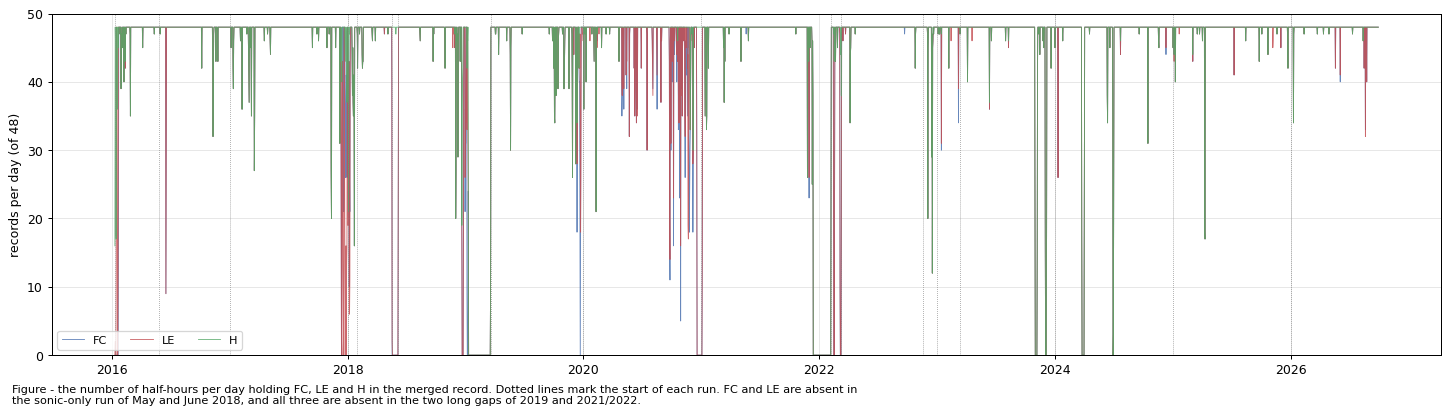

In [11]:
fig, ax = plt.subplots(figsize=(16, 4.5), dpi=90, layout='constrained')
for _c, _col in zip(FLUXCOLS, ['#4C72B0', '#C44E52', '#55A868']):
    _n = df[_c].resample('D').count()
    ax.plot(_n.index, _n.values, lw=0.7, color=_col, label=_c, alpha=.85)
for _run in runs:
    _lo = KEEP[_run][0] or runs[_run].index[0]
    ax.axvline(_lo, color='0.5', lw=0.6, ls=':')
ax.set_ylabel('records per day (of 48)')
ax.set_ylim(0, 50)
ax.legend(loc='lower left', ncol=3, fontsize=9)
ax.grid(alpha=.3)
figcap(fig, "the number of half-hours per day holding FC, LE and H in the merged record. Dotted lines "
            "mark the start of each run. FC and LE are absent in the sonic-only run of May and June "
            "2018, and all three are absent in the two long gaps of 2019 and 2021/2022.")
plt.show()

## 💾 Export

In [12]:
Path(OUTPATH).mkdir(parents=True, exist_ok=True)
filepath = save_parquet(filename=OUTNAME, data=df, outpath=OUTPATH)
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.1_FLUXES_IRGA72_L1_2016-2026.09.parquet (3.289 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRGA72\22.1_FLUXES_IRGA72_L1_2016-2026.09.parquet


## ✅ Read the written file back

In [13]:
_written = load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"index:   {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"columns: {len(_written.columns):,}")

assert _written.index.equals(df.index), "index changed on write"
assert list(_written.columns) == list(df.columns), "columns changed on write"
for _c in FLUXCOLS:
    assert _written[_c].equals(df[_c]), f"{_c} changed on write"
print("\nWritten file verified.")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.1_FLUXES_IRGA72_L1_2016-2026.09.parquet (0.276 seconds).

index:   2016-01-11 15:45:00 -> 2026-09-30 23:45:00  (187,937 records)
columns: 329

Written file verified.


***

# End of notebook.

In [14]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-25 02:03:34
Finished: 2026-10-25 02:04:31
Runtime:  00:00:56 (hh:mm:ss)
